# Autoencoders and Image Reconstruction

This notebook explores neural networks for image classification, representation learning, and reconstruction. It first builds a fully connected classifier for MNIST, then uses an autoencoder to reconstruct handwritten digits, and finally trains a convolutional denoising autoencoder on CIFAR-10.

The code uses PyTorch for model building and training, scikit-learn for dimensionality reduction, and Matplotlib for visualization. The notebook selects a GPU when CUDA is available and otherwise runs on the CPU.

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
from tqdm import trange

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader

from torchvision import transforms, models
from torchvision.datasets.mnist import MNIST
from torchvision.datasets.cifar import CIFAR10

torch.manual_seed(0)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

## Visualization and Evaluation Utilities

These helper functions make it easier to inspect training progress and learned representations:

- `plot_history` displays training and test loss, and accuracy when those metrics are available.
- `plot_conf_mat` builds a normalized confusion matrix for a 10-class classifier.
- `visualize` plots two-dimensional representations and colors points by their labels.
- `plot_last_hidden_layer` reduces classifier features with PCA or t-SNE.
- `plot_autoencoder` visualizes the autoencoder's encoded representations.
- `plot_reconstruction` compares original images with reconstructed images, optionally after adding noise.

The functions are defined here so later cells can reuse them.

In [ ]:
def plot_history(history):
    if 'train_acc' in history:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        ax1.plot(history['train_loss'], label='train')
        ax1.plot(history['test_loss'], label='test')
        ax1.set_xlabel('Epochs')
        ax1.set_ylabel('Loss')
        ax1.legend()
        ax2.plot(history['train_acc'], label='train')
        ax2.plot(history['test_acc'], label='test')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
    else:
        plt.plot(history['train_loss'], label='train')
        plt.plot(history['test_loss'], label='test')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
    plt.show()


def plot_conf_mat(model, dataloader, device=device):
    total, correct = 0, 0
    conf_mat = torch.zeros((10, 10))
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            total += pred.shape[0]
            pred = torch.argmax(pred, axis=1)
            correct += sum(pred == y).item()
            for j in range(pred.shape[0]):
                conf_mat[y[j], pred[j].item()] += 1
    # calculate the normalized confusion matrix
    norm_conf_mat = conf_mat / torch.sum(conf_mat, axis=1)
    # plot the matrix
    fig, ax = plt.subplots()
    plt.imshow(norm_conf_mat)
    plt.title('Confusion Matrix')
    plt.xlabel('Predictions')
    plt.ylabel('Labels')
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.colorbar()
    # put number of each cell in plot
    for i in range(10):
        for j in range(10):
            c = conf_mat[j, i]
            color = 'black' if c > 500 else 'white'
            ax.text(i, j, str(int(c)), va='center', ha='center', color=color)
    plt.show()


def visualize(embedded, labels, title=''):
    fig, ax = plt.subplots(figsize=(12,8))

    # get discrete colormap
    cmap = plt.get_cmap('jet', 10) # virdis

    # plot scatter points
    scatter = ax.scatter(embedded[:, 0], embedded[:, 1], c=labels, cmap=cmap)

    # add colorbar
    cbar = plt.colorbar(scatter)

    # set ticks locations
    cbar.set_ticks((np.arange(10) + 0.5) * (10 - 1) / 10)

    # set tick labels
    cbar.set_ticklabels([str(i) for i in range(10)])

    plt.title(title)
    plt.show()


def plot_last_hidden_layer(model, dataloader, method='PCA'):
    with torch.no_grad():
        encoded_data, labels = [], []
        for imgs, lbls in dataloader:
            encoded = model.last_hidden_layer(imgs.to(device))
            encoded_data.append(encoded.cpu().numpy())
            labels.append(lbls.cpu().numpy())

    # Concatenate the encoded representations and labels
    encoded_data = np.concatenate(encoded_data, axis=0)
    labels = np.concatenate(labels, axis=0)

    if method == 'PCA':
        embedded = PCA(n_components=2).fit_transform(encoded_data)
        title = 'Reduction of the Last Hidden Layer using PCA'
    else:
        embedded = TSNE(n_components=2, learning_rate='auto', init='random',
                        perplexity=3).fit_transform(encoded_data)
        title = 'Reduction of the Last Hidden Layer using t-SNE'

    visualize(embedded, labels, title)


def plot_autoencoder(model, dataloader, method='PCA', denoising=False):
    with torch.no_grad():
        encoded_data, labels = [], []
        for imgs, lbls in dataloader:
            encoded = model.encoder(imgs.to(device))
            if denoising:
                encoded = encoded.view(encoded.size(0), -1)
            encoded_data.append(encoded.cpu().numpy())
            labels.append(lbls.cpu().numpy())

    # Concatenate the encoded representations and labels
    encoded_data = np.concatenate(encoded_data, axis=0)
    labels = np.concatenate(labels, axis=0)

    if encoded_data.shape[1] == 2:
        embedded = encoded_data
        title = 'Latent Space'
    elif method == 'PCA':
        embedded = PCA(n_components=2).fit_transform(encoded_data)
        title = 'Reduction of the Latent Space using PCA'
    else:
        embedded = TSNE(n_components=2, learning_rate='auto', init='random',
                        perplexity=3).fit_transform(encoded_data)
        title = 'Reduction of the Latent Space using t-SNE'

    visualize(embedded, labels, title)



def plot_reconstruction(model, dataset, denoising=False, mask=False):
    # Choose 10 random samples
    random_indices = np.random.choice(len(dataset), size=10, replace=False)

    # Get images and labels for the chosen samples
    images = [dataset[i][0] for i in random_indices]
    labels = [dataset[i][1] for i in random_indices]

    is_grayscale = images[0].shape[0]==1
    cmap = 'gray' if is_grayscale else None

    if denoising:
        noisy_images = [add_noise(image, mask=mask) for image in images]

    # Reconstruct the images using the autoencoder
    with torch.no_grad():
        if denoising:
            reconstructed_images = [model(noisy_image.unsqueeze(0).to(device)).squeeze().cpu() for noisy_image in noisy_images]
        else:
            reconstructed_images = [model(image.unsqueeze(0).to(device)).squeeze().cpu() for image in images]

    if denoising:
        # Display the original and reconstructed images
        fig, axes = plt.subplots(3, 10, figsize=(15, 5))

        # First row: Original images
        for i, image in enumerate(images):
            if is_grayscale:
                axes[0, i].imshow(image.squeeze().numpy(), cmap=cmap)
            else:
                axes[0, i].imshow(image.permute(1,2,0).numpy(), cmap=cmap)
            axes[0, i].set_title(f"Original {classes[labels[i]]}")
            axes[0, i].axis('off')

        # Second row: Noisy images
        for i, image in enumerate(noisy_images):
            if is_grayscale:
                axes[1, i].imshow(image.squeeze().numpy(), cmap=cmap)
            else:

                axes[1, i].imshow(image.permute(1,2,0).numpy(), cmap=cmap)
            axes[1, i].set_title(f"Noisy {classes[labels[i]]}")
            axes[1, i].axis('off')

        # Third row: Reconstructed images
        for i, image in enumerate(reconstructed_images):
            if is_grayscale:
                axes[2, i].imshow(image.squeeze().numpy().reshape(28, 28), cmap=cmap)
            else:
                axes[2, i].imshow(image.permute(1,2,0).numpy(), cmap=cmap)
            axes[2, i].set_title(f"Reconstructed")
            axes[2, i].axis('off')

    else:
        # Display the original and reconstructed images
        fig, axes = plt.subplots(2, 10, figsize=(15, 3))

        # First row: Original images
        for i, image in enumerate(images):
            if is_grayscale:
                axes[0, i].imshow(image.squeeze().numpy(), cmap=cmap)
            else:
                axes[0, i].imshow(image.permute(1,2,0).numpy(), cmap=cmap)
            axes[0, i].set_title(f"Label: {classes[labels[i]]}")
            axes[0, i].axis('off')

        # Second row: Reconstructed images
        for i, image in enumerate(reconstructed_images):
            if is_grayscale:
                axes[1, i].imshow(image.detach().numpy().reshape(28, 28), cmap=cmap)
            else:
                axes[1, i].imshow(image.detach().numpy(), cmap=cmap)
            axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

## Load the MNIST Dataset

This cell downloads MNIST if it is not already present in `./data`. It creates separate training and test datasets, converts each image to a PyTorch tensor, and wraps the datasets in `DataLoader` objects.

The training loader shuffles examples each epoch, while the test loader preserves their order. A batch size of 256 is used. The `classes` tuple lists the ten digit labels, from 0 through 9.

In [ ]:
batch_size = 256

trainset = MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

classes = ('0', '1', '2', '3', '4', '5', '6', '7', '8', '9')

100%|██████████| 9.91M/9.91M [00:14<00:00, 695kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 45.5kB/s]
100%|██████████| 1.65M/1.65M [00:06<00:00, 252kB/s] 
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


## Define a Fully Connected MNIST Classifier

`Network` is a feed-forward neural network for classifying 28 × 28 grayscale MNIST images.

The feature extractor flattens each image into 784 values and maps it through fully connected layers of sizes 256 and 64, using ReLU activations. The final layer produces ten output scores, one for each digit class.

`last_hidden_layer` exposes the 64-dimensional feature representation so it can be visualized later. `forward` sends those features through the final classification layer.

In [5]:
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        self.fe = nn.Sequential(nn.Linear(784, 256),
                                nn.ReLU(inplace=True),
                                nn.Linear(256, 64),
                                nn.ReLU(inplace=True))
        self.fc = nn.Linear(64, 10)

    def last_hidden_layer(self, x):
        x = torch.flatten(x, start_dim=1) / 255.
        return self.fe(x)

    def forward(self, x):
        out = self.last_hidden_layer(x)
        out = self.fc(out)
        return out

## Training and Testing the Classifier

These functions implement the classifier's training and evaluation loops.

- `classifier_train_step` enables training mode, calculates predictions and cross-entropy loss, backpropagates gradients, updates the model, and reports average loss and accuracy for the training dataset.
- `classifier_test_step` evaluates the model without updating its weights, using inference mode to avoid gradient calculations.
- `train_classifier` creates the Adam optimizer and cross-entropy loss function, repeats training and testing for the requested number of epochs, and stores the metrics in a history dictionary.

The history is later used to plot how the model performs over time.

In [ ]:
def classifier_train_step(model, dataloader, loss_fn, optimizer, device):
    model.train()
    train_loss = 0.
    train_acc = 0.
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        train_loss += loss.item()
        train_acc += (logits.argmax(dim=1) == labels).sum().item()
    train_loss /= len(dataloader)
    train_acc /= len(dataloader.dataset)
    return train_loss, train_acc


def classifier_test_step(model, dataloader, loss_fn, device):
    model.eval()
    test_loss = 0.
    test_acc = 0.
    with torch.inference_mode():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = loss_fn(logits, labels)
            test_loss += loss.item()
            test_acc += (logits.argmax(dim=1) == labels).sum().item()
        test_loss /= len(dataloader)
        test_acc /= len(dataloader.dataset)
    return test_loss, test_acc


def train_classifier(model, train_dataloader, test_dataloader, n_epochs, device=device):
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    optimizer = Adam(model.parameters())
    loss_fn = CrossEntropyLoss()
    for _ in (pbar := trange(n_epochs)):
        train_loss, train_acc = classifier_train_step(model, train_dataloader, loss_fn, optimizer, device)
        history['train_loss'].append(train_loss), history['train_acc'].append(train_acc)
        test_loss, test_acc = classifier_test_step(model, test_dataloader, loss_fn, device)
        history['test_loss'].append(test_loss), history['test_acc'].append(test_acc)
        pbar.set_description(f'Training Accuracy {100 * train_acc:.2f}% | Test Accuracy {100 * test_acc:.2f}% ')
    return history

## Train the MNIST Classifier

This cell creates a `Network`, moves it to the selected device, and trains it for 30 epochs using the MNIST training and test loaders.

The resulting history contains loss and accuracy for both datasets. `plot_history` visualizes these metrics so you can assess learning progress and compare training performance with test performance.

Training Accuracy 95.05% | Test Accuracy 94.83% : 100%|██████████| 30/30 [03:16<00:00,  6.56s/it]


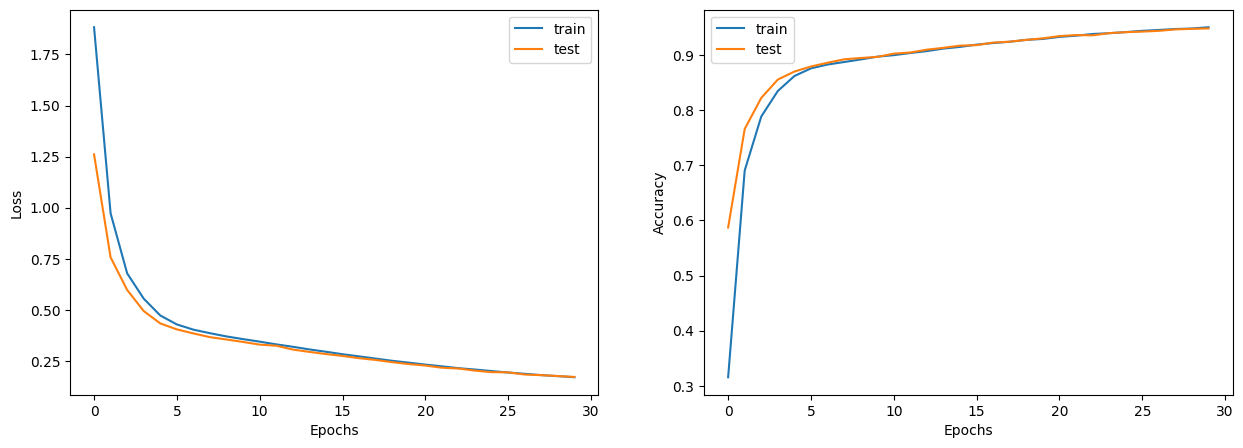

In [7]:
net = Network().to(device)

results = train_classifier(net, trainloader, testloader, n_epochs=30)
plot_history(results)

## Evaluate Classification Errors with a Confusion Matrix

This cell calls `plot_conf_mat` on the trained classifier and MNIST test data. The confusion matrix compares each true digit label with the model's predicted label.

The diagonal represents correct classifications; off-diagonal entries show which digits are being confused with one another. This helps reveal error patterns that a single overall accuracy score may hide.

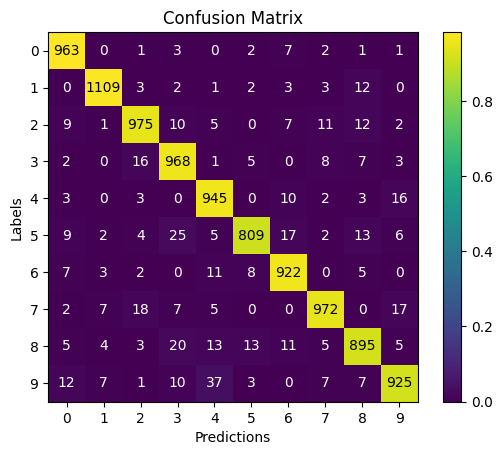

In [8]:
plot_conf_mat(net, testloader)

## Visualize Classifier Features with PCA

This cell extracts the trained classifier's last hidden-layer features for the test images and projects them into two dimensions using Principal Component Analysis (PCA).

Each point represents an image, colored by its true digit label. The plot helps you inspect whether images from different digit classes form distinguishable groups in the learned feature space.

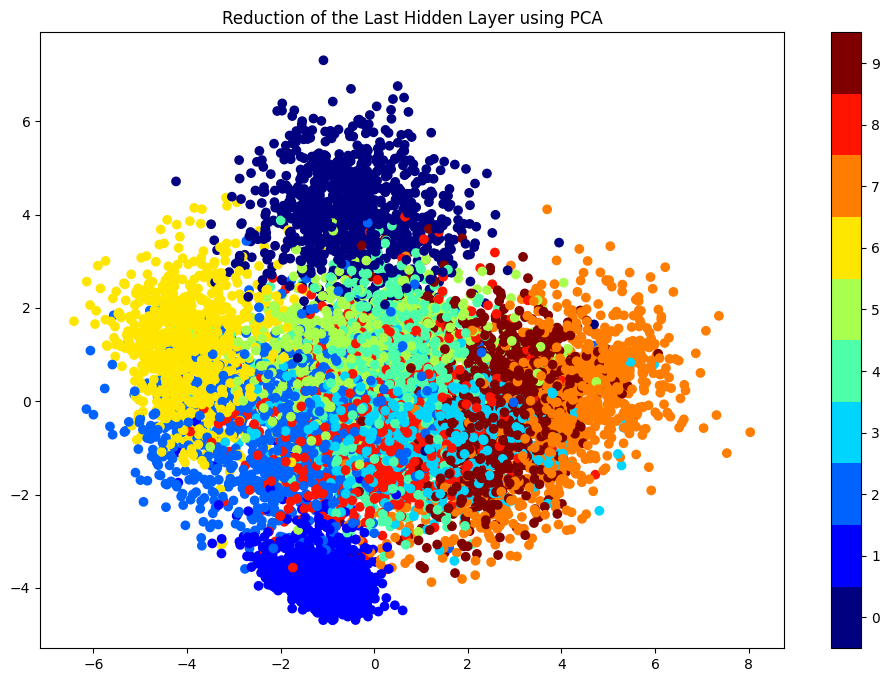

In [9]:
plot_last_hidden_layer(net, testloader, method='PCA')

## Visualize Classifier Features with t-SNE

This cell repeats the feature visualization using t-distributed Stochastic Neighbor Embedding (t-SNE) instead of PCA.

t-SNE is a nonlinear dimensionality-reduction method that often emphasizes local neighborhoods in high-dimensional data. Compare this plot with the PCA result, remembering that the two methods preserve different aspects of the original feature space.

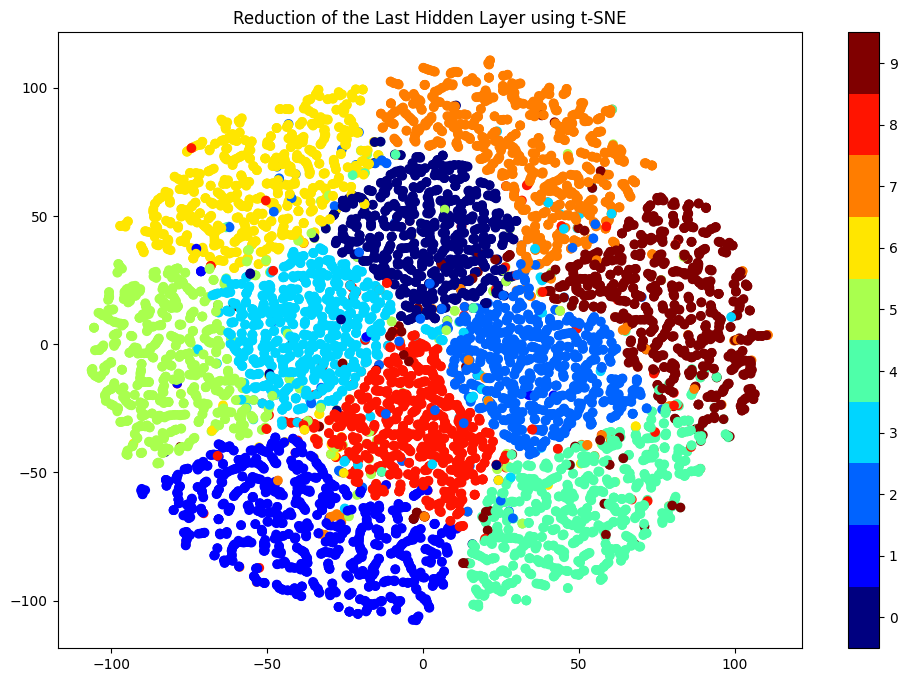

In [10]:
plot_last_hidden_layer(net, testloader, method='t-SNE')

## Define a Fully Connected Autoencoder for MNIST

An autoencoder learns to compress an input into a latent representation and then reconstruct the input from that representation.

The encoder flattens each 28 × 28 image and maps it through layers of 256 and 64 units to a 16-dimensional latent vector. The decoder reverses this process, expanding the vector back to 784 values and reshaping it into a grayscale image. The final sigmoid activation constrains reconstructed pixel values to the range from 0 to 1.

Unlike the classifier, this model is trained to reproduce its input rather than predict a digit label.

In [11]:
class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        # The Encoder Network
        self.encoder = nn.Sequential(nn.Flatten(),
                                     nn.Linear(28 * 28, 256),
                                     nn.ReLU(inplace=True),
                                     nn.Linear(256, 64),
                                     nn.ReLU(inplace=True),
                                     nn.Linear(64, 16),)
        # The Decoder Network
        self.decoder = nn.Sequential(nn.Linear(16, 64),
                                     nn.ReLU(inplace=True),
                                     nn.Linear(64, 256),
                                     nn.ReLU(inplace=True),
                                     nn.Linear(256, 28 * 28),
                                     nn.Unflatten(1, (1, 28, 28)),
                                     nn.Sigmoid())

    def forward(self, x):
        out = self.decoder(self.encoder(x))
        return out

## Create Corruption Functions and Autoencoder Training Loops

This cell defines the tools used to train standard and denoising autoencoders.

- `mask_image` hides randomly placed square regions of an image.
- `add_noise` can apply Gaussian, salt-and-pepper, speckle, Poisson, square-mask, or blur corruption, then clips values to the image range.
- `autoencoder_train_step` feeds either clean or corrupted images to the model and compares the reconstruction with the original clean image.
- `autoencoder_test_step` evaluates reconstruction loss on the test set.
- `train_autoencoder` trains with Adam and mean squared error (MSE), recording training and test loss each epoch.

When denoising is enabled, the input is corrupted but the target remains the original image. This teaches the model to recover a clean image from a noisy input.

In [ ]:
def mask_image(x, square_size=5, number_of_squares=3):
    masked = x.clone()
    for _ in range(number_of_squares):
        start_i = torch.randint(0, x.shape[-2]-square_size, (1, ))
        start_j = torch.randint(0, x.shape[-1]-square_size, (1, ))
        masked[..., start_i:start_i+square_size, start_j:start_j+square_size]=0
    return masked

def add_noise(x, mask= False):
    if mask:
        return mask_image(x)

    select_mode = np.random.uniform()

    if select_mode <= 1/6: # gaussian noise
        noisy = x + torch.randn_like(x) * 0.5

    elif select_mode <= 2/6: # salt and pepper noise
        noise = torch.rand_like(x)
        noisy = x.clone()
        noisy[noise < 0.1] = 0
        noisy[noise > 0.9] = 1

    elif select_mode <= 3/6: # speckle noise
        noisy = x + x*torch.randn_like(x)

    elif select_mode <= 4/6: # poisson
        noisy = torch.poisson(x * 2)/2

    elif select_mode <= 5/6: # square masking
        noisy = mask_image(x, square_size=4, number_of_squares=4)

    else: # bluring
        noisy = transforms.GaussianBlur(5, sigma=(2,2))(x)

    noisy[noisy < 0] = 0
    noisy[noisy > 1] = 1
    return noisy

def autoencoder_train_step(model, dataloader, loss_fn, optimizer, denoising, mask, device):
    model.train()
    train_loss = 0.
    for images, _ in dataloader:
        images = images.to(device)
        if denoising: # Add noise to the images
            noisy_images = add_noise(images, mask= mask)
            recons = model(noisy_images)
        else:
            recons = model(images)
        loss = loss_fn(recons, images)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        train_loss += loss.item()
    train_loss /= len(dataloader)
    return train_loss


def autoencoder_test_step(model, dataloader, loss_fn, denoising, mask, device):
    model.eval()
    test_loss = 0.
    with torch.inference_mode():
        for images, _ in dataloader:
            images = images.to(device)
            if denoising: # Add noise to the images
                noisy_images = add_noise(images, mask=mask)
                recons = model(noisy_images)
            else:
                recons = model(images)
            loss = loss_fn(recons, images)
            test_loss += loss.item()
        test_loss /= len(dataloader)
    return test_loss


def train_autoencoder(model, train_dataloader, test_dataloader, n_epochs, denoising=False, mask=False, device=device):
    history = {'train_loss': [], 'test_loss': []}
    optimizer = Adam(model.parameters())
    loss_fn = nn.MSELoss()
    for _ in (pbar := trange(n_epochs)):
        train_loss = autoencoder_train_step(model, train_dataloader, loss_fn, optimizer, denoising, mask, device)
        history['train_loss'].append(train_loss)
        test_loss = autoencoder_test_step(model, test_dataloader, loss_fn, denoising, mask, device)
        history['test_loss'].append(test_loss)
        pbar.set_description(f'Training Loss {train_loss:.3f} | Test Loss {test_loss:.3f} ')
    return history


## Train the Standard MNIST Autoencoder

This cell initializes the fully connected `AutoEncoder` and trains it for 30 epochs with denoising disabled. The model receives clean MNIST images and learns to reconstruct those same images.

The training history is plotted to show the reconstruction loss on the training and test sets over time.

Training Loss 0.011 | Test Loss 0.011 : 100%|██████████| 30/30 [03:43<00:00,  7.45s/it]


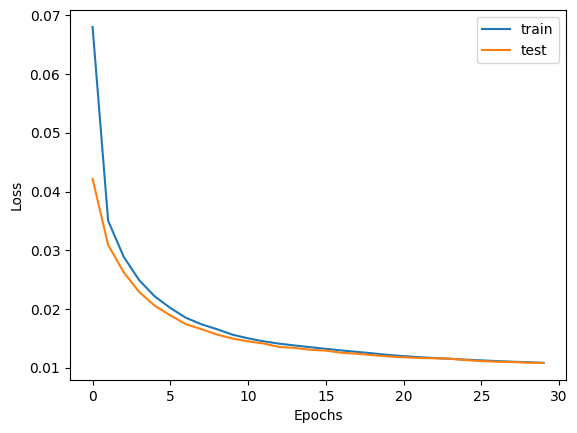

In [13]:
autoencoder = AutoEncoder().to(device)

res = train_autoencoder(autoencoder, trainloader, testloader, n_epochs=30)
plot_history(res)

## Inspect Reconstructions of Training Images

This cell displays reconstructions of ten randomly selected images from the MNIST training dataset.

Comparing the original images with their reconstructions gives a visual sense of how well the autoencoder preserves digit shape and detail on examples it was trained on.

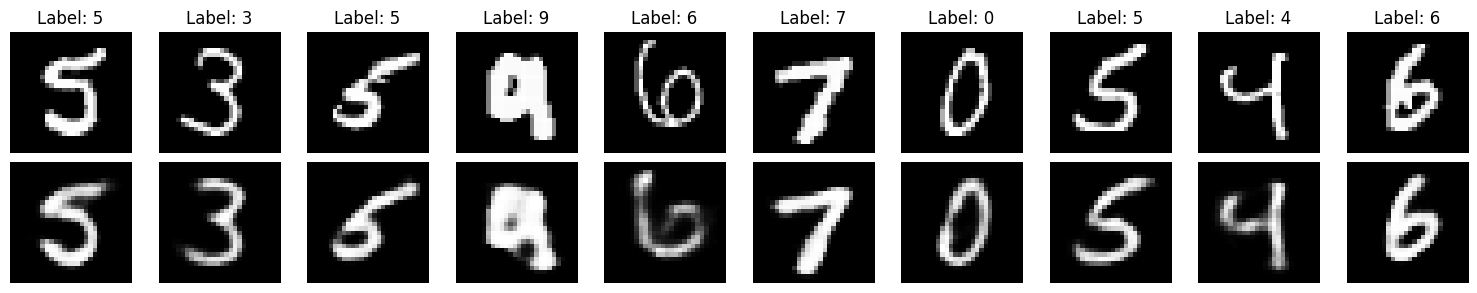

In [14]:
plot_reconstruction(autoencoder, trainset)

## Inspect Reconstructions of Test Images

This cell visualizes reconstructions for randomly selected images from the MNIST test dataset.

Because these images were held out from training, the results provide a useful qualitative check of how well the autoencoder reconstructs unseen examples.

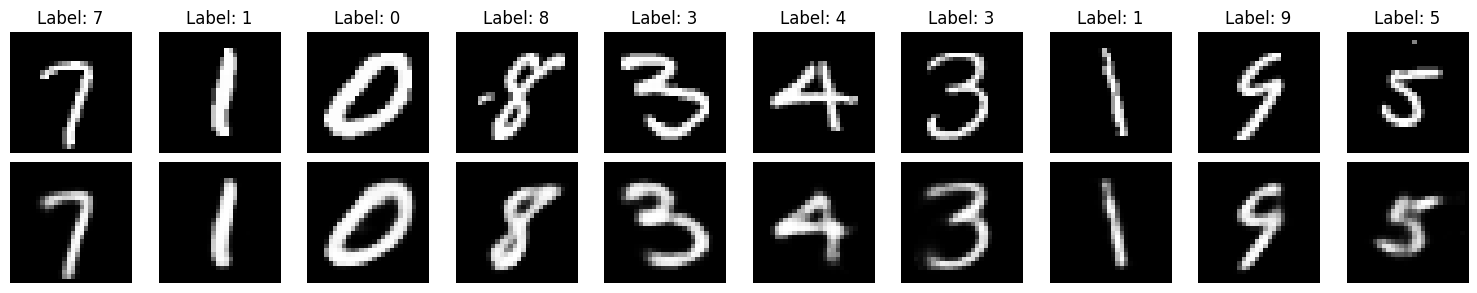

In [15]:
plot_reconstruction(autoencoder, testset)

## Visualize the Autoencoder Latent Space with PCA

This cell extracts latent representations from the MNIST test set and uses PCA to reduce them to two dimensions for plotting.

Points are colored by digit label. The autoencoder is trained for reconstruction, not classification, so any grouping by digit is an emergent property of the learned representations rather than a directly optimized objective.

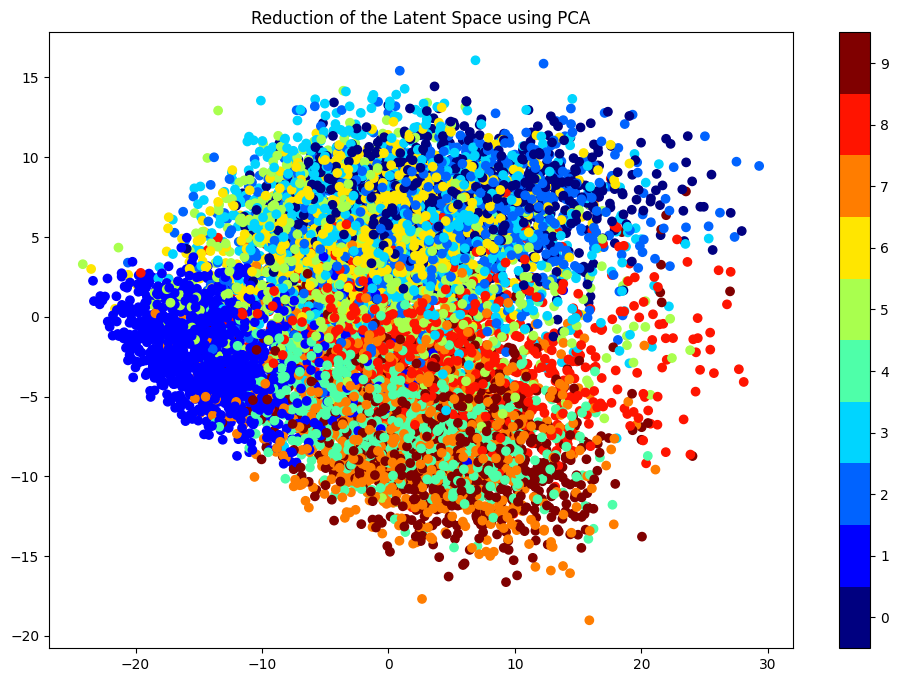

In [16]:
plot_autoencoder(autoencoder, testloader, method='PCA')

## Visualize the Autoencoder Latent Space with t-SNE

This cell visualizes the autoencoder's latent representations with t-SNE. Compare the resulting two-dimensional arrangement with the PCA visualization.

These plots can help explore the structure of the representation, but the visible clusters are qualitative and do not by themselves measure reconstruction quality or classification accuracy.

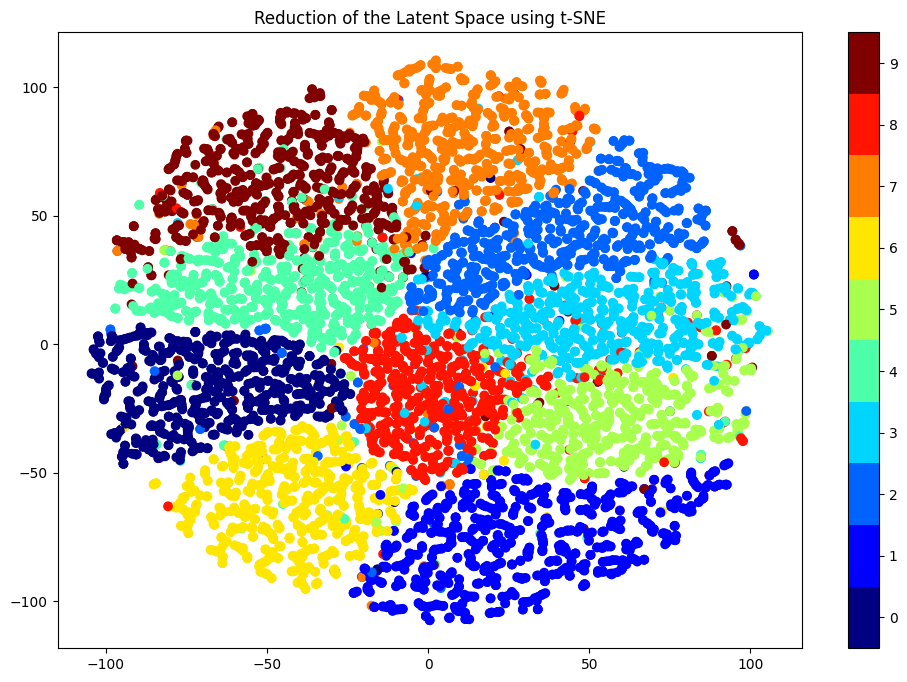

In [17]:
plot_autoencoder(autoencoder, testloader, method='t-SNE')

## Test the Standard Autoencoder on Corrupted Images

This cell passes corrupted MNIST test images to the trained standard autoencoder and displays the resulting reconstructions.

The model was trained on clean inputs, so this is an exploratory test of how it responds to corruption—not a model specifically trained for denoising. The comparison can illustrate the difference between ordinary reconstruction training and denoising training.

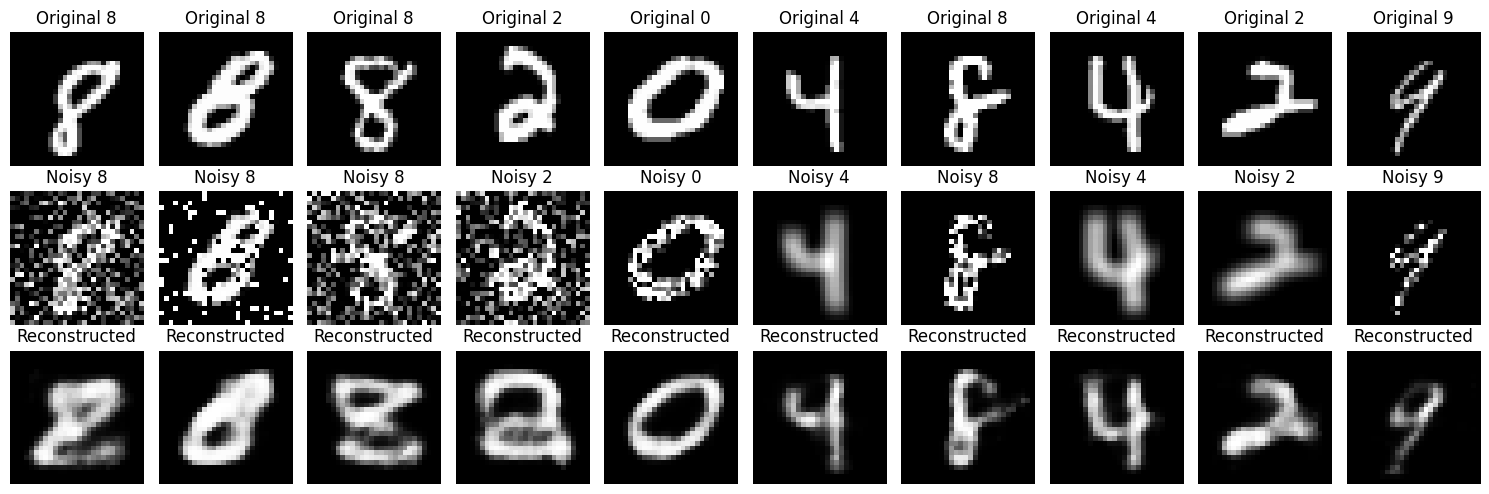

In [18]:
plot_reconstruction(autoencoder, testset, denoising=True)

## Train a Denoising Autoencoder on MNIST

This cell initializes a fresh `AutoEncoder` and trains it with `denoising=True`. During training, corrupted images are supplied as inputs, while the corresponding clean images remain the reconstruction targets.

The loss curves show whether the model learns to reconstruct clean digits from noisy inputs over the 30 training epochs.

Training Loss 0.017 | Test Loss 0.016 : 100%|██████████| 30/30 [03:47<00:00,  7.57s/it]


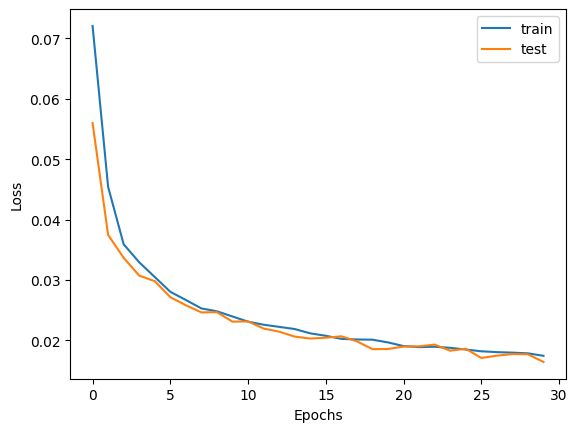

In [19]:
dae = AutoEncoder().to(device)

res = train_autoencoder(dae, trainloader, testloader, n_epochs=30, denoising=True)
plot_history(res)

## Evaluate MNIST Denoising Reconstructions

This cell visualizes denoising results from the trained `dae` model on MNIST test images. Each selected image is corrupted before being passed to the model, and the reconstruction is compared with the clean image.

Use this result to assess qualitatively whether the model removes noise while preserving the important structure of each digit.

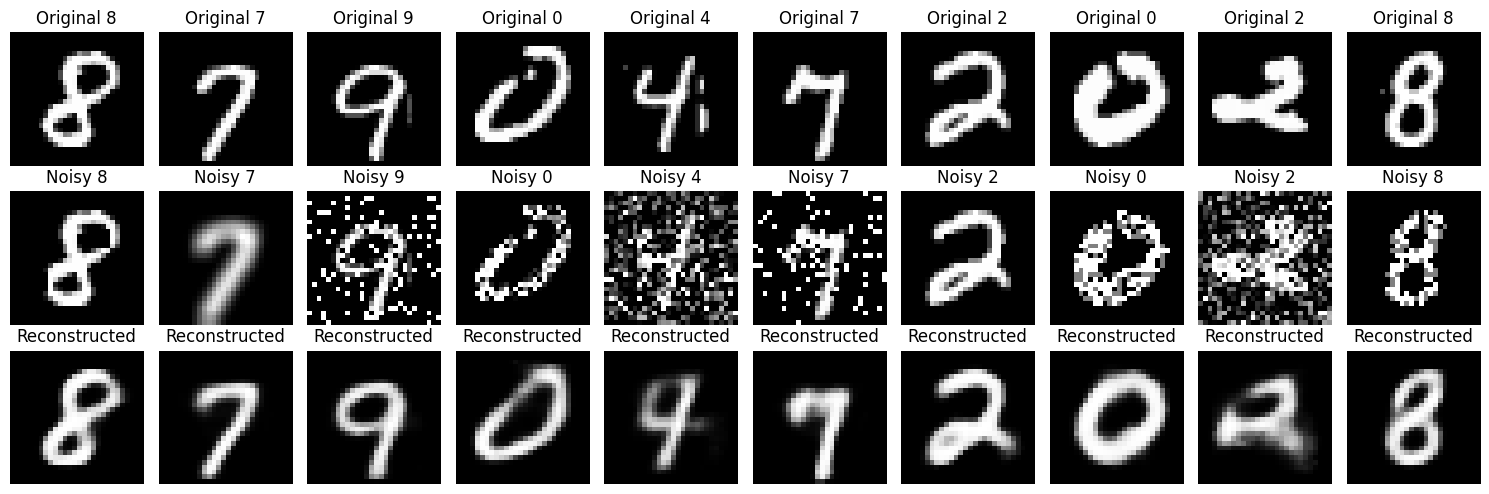

In [20]:
plot_reconstruction(dae, testset, denoising=True)

## Switch the Data Pipeline to CIFAR-10

This cell replaces the MNIST datasets and loaders with CIFAR-10. CIFAR-10 contains 32 × 32 color images from ten categories, including airplanes, cars, birds, cats, dogs, and ships.

The images are converted to tensors, and the same batch size of 256 is used. The `classes` tuple records the dataset's category names. The following model is designed for three-channel color images rather than one-channel MNIST digits.

In [22]:
# @title CIFAR10 dataset
batch_size = 256

trainset = CIFAR10(root='./data', train=True, download=True, transform=transforms.ToTensor())
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = CIFAR10(root='./data', train=False, download=True, transform=transforms.ToTensor())
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


## Define a Convolutional Denoising Autoencoder for CIFAR-10

This model uses convolutional layers to encode 32 × 32 RGB images into compact spatial feature maps. Three stride-2 convolution layers reduce the spatial dimensions from 32 × 32 to 16 × 16, 8 × 8, and 4 × 4 while increasing the number of feature channels.

The decoder uses transposed convolutions to upsample the feature maps back to 32 × 32 with three color channels. A sigmoid activation constrains the reconstructed pixel values to the range from 0 to 1.

This convolutional architecture is suited to images because it can learn spatial patterns such as edges, textures, and object parts.

In [23]:
class DenoisingAutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        # The Encoder Network
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=2, padding=1),  # (32x32x3) -> (16x16x64)
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=2, padding=1),  # (16x16x64) -> (8x8x128)
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=2, padding=1),  # (8x8x128) -> (4x4x256)
            nn.ReLU(inplace=True)
        )

        # The Decoder Network
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=3, stride=2, padding=1, output_padding=1),  # (4x4x256) -> (8x8x128)
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=3, stride=2, padding=1, output_padding=1),  # (8x8x128) -> (16x16x64)
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64, out_channels=3, kernel_size=3, stride=2, padding=1, output_padding=1),  # (16x16x64) -> (32x32x3)
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.decoder(self.encoder(x))
        return out

## Train the CIFAR-10 Denoising Autoencoder with Masking

This cell initializes the convolutional `DenoisingAutoEncoder` and trains it for 30 epochs on CIFAR-10. With `denoising=True` and `mask=True`, square regions are masked in the input images, while the model is trained to reconstruct the original unmasked images.

The plotted history tracks training and test reconstruction loss, providing a way to monitor how well the model learns to restore missing image regions.

  0%|          | 0/30 [00:00<?, ?it/s]

Training Loss 0.002 | Test Loss 0.002 : 100%|██████████| 30/30 [03:44<00:00,  7.50s/it]


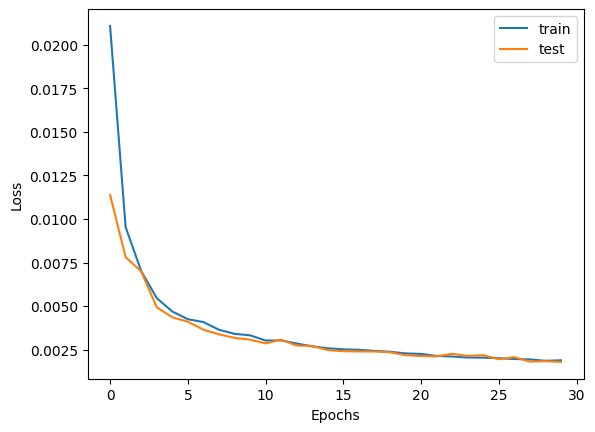

In [24]:
dae = DenoisingAutoEncoder().to(device)

res = train_autoencoder(dae, trainloader, testloader, n_epochs=30, denoising=True, mask=True)
plot_history(res)

## Visualize CIFAR-10 Masked-Image Reconstructions

This final cell displays denoising reconstructions from the trained convolutional autoencoder on CIFAR-10 test images. Square regions are masked before inference, and the model attempts to reconstruct the original color images.

Inspect the original, masked, and reconstructed images to judge how well the model restores missing regions and preserves image content.

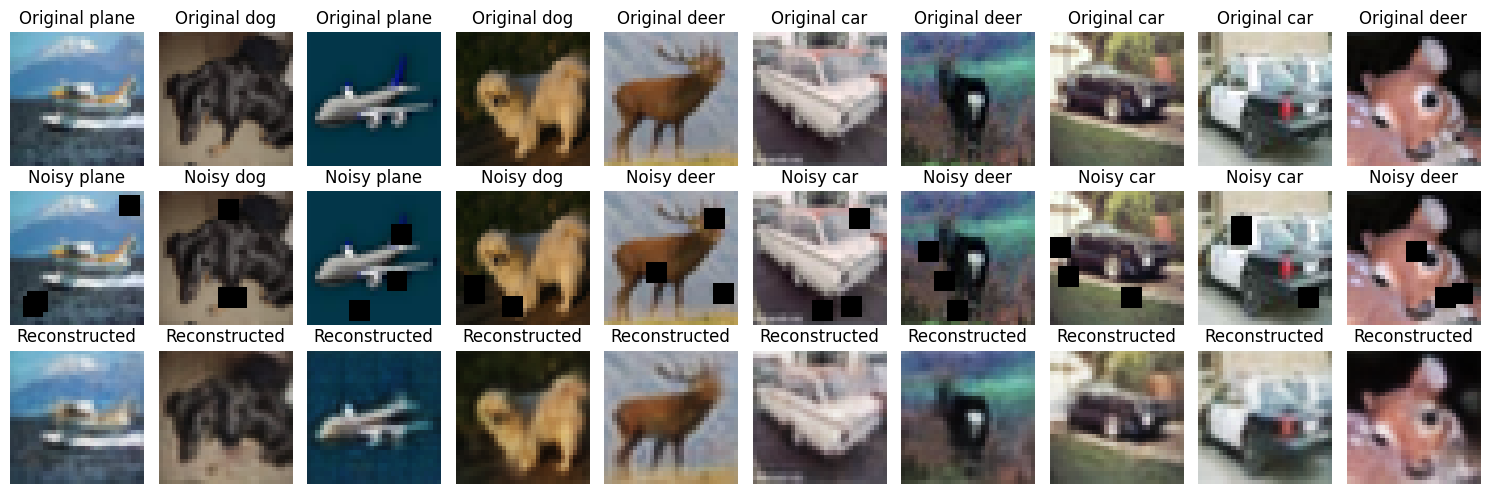

In [25]:
plot_reconstruction(dae, testset, denoising=True, mask=True)